# Causal Inference | Doubly Robust Promotion Effect

> **Portfolio case study · Synthetic demonstration data**  
> **Business problem:** Did a targeted CRM offer cause additional purchases when marketing selected customers based on prior behavior?

### Decisions this project supports
- Measure confounding, propensity overlap, and covariate imbalance.
- Estimate ATE with cross-fitted augmented inverse-propensity weighting (AIPW).
- Discover which segments might benefit most and clarify identifiability risks.

**Methods & skills:** confounding · propensity score · cross-fitting · AIPW / influence function · CATE analysis  
**Data:** generated locally with a fixed seed; no external credentials, downloads, or paid services required.  
**Reproducibility:** run cells in order with Python 3.10+ and packages in `requirements.txt`.

**Scope & interpretation:** This dependency-light AIPW demonstration preserves the **estimand and doubly-robust reasoning** of the original EconML/DoWhy notebook, but does not call those packages. Causal interpretation assumes conditional exchangeability, positivity and consistent treatment definitions; synthetic truth is known for checks.

**Original topic:** [Causal_inference_econml_dowhy.ipynb](https://github.com/tamtran4869/marketing_effectiveness_analysis/blob/main/Causal_inference_econml_dowhy.ipynb)

---


## 1. Setup & reproducible data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.labelcolor": "#243047",
    "axes.titlesize": 13, "font.size": 10,
    "grid.alpha": 0.2,
})
COLORS = ["#1B4965", "#14B8A6", "#F59E0B", "#D75A5A", "#7C6FC6", "#64748B"]

def format_number(value, decimals=0):
    return f"{value:,.{decimals}f}"

def section(title, message):
    display(Markdown(f"**{title}** — {message}"))

In [2]:
from scipy.special import expit
from scipy.stats import norm
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
n=13000
X=pd.DataFrame({
 'orders_90d':rng.poisson(2.5,n),
 'tenure_months':rng.uniform(1,48,n),
 'recency_days':rng.uniform(1,150,n),
 'avg_basket':rng.lognormal(4.0,.55,n)
})
prop=expit(-.75+.22*X.orders_90d+.025*X.tenure_months-.015*X.recency_days+.004*X.avg_basket)
T=rng.binomial(1,prop)
p0=expit(-2.5+.30*X.orders_90d+.01*X.tenure_months-.012*X.recency_days+.003*X.avg_basket)
tau=.06+.07*(X.orders_90d<=2)+.05*(X.recency_days<60)
p1=np.minimum(p0+tau,.97)
Y=rng.binomial(1,np.where(T,p1,p0))
df=X.assign(offer=T,purchase=Y,known_tau=p1-p0)
features=list(X.columns)
section('Data generation',f'{n:,} customers, observed offer rate {T.mean():.1%}; synthetic population true ATE {df.known_tau.mean():.2%}.')

**Data generation** — 13,000 customers, observed offer rate 39.7%; synthetic population true ATE 11.79%.

## 2. Confounding and overlap diagnostic

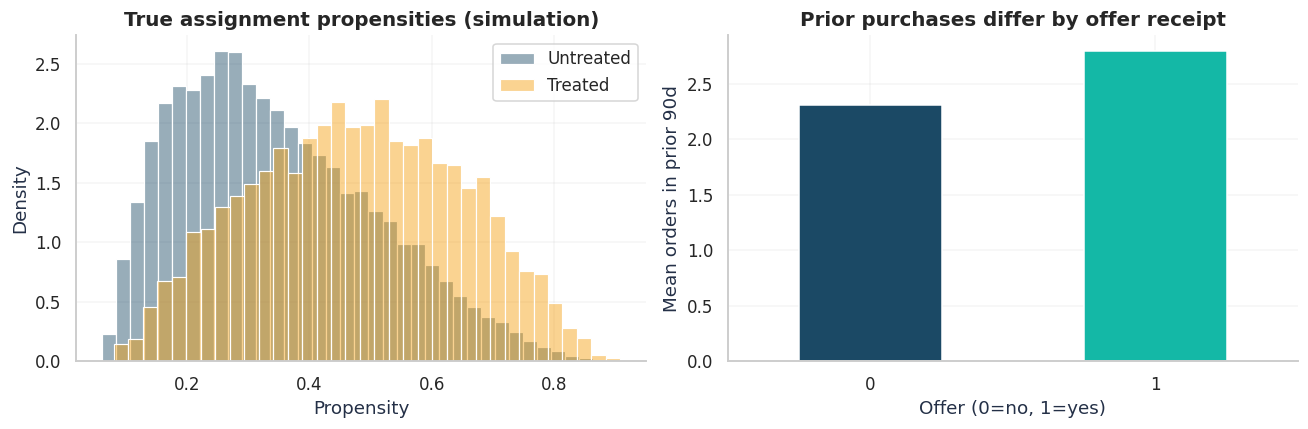

**Naive association** — Treated minus control purchase rate = 16.48%; confounding means it need not equal the average treatment effect.

In [3]:
naive=df.loc[df.offer==1,'purchase'].mean()-df.loc[df.offer==0,'purchase'].mean()
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.histplot(prop[T==0],bins=35,stat='density',alpha=.45,ax=axes[0],label='Untreated',color=COLORS[0])
sns.histplot(prop[T==1],bins=35,stat='density',alpha=.45,ax=axes[0],label='Treated',color=COLORS[2])
axes[0].set(title='True assignment propensities (simulation)',xlabel='Propensity');axes[0].legend()
df.groupby('offer').orders_90d.mean().plot.bar(ax=axes[1],rot=0,color=COLORS[:2]);axes[1].set(title='Prior purchases differ by offer receipt',xlabel='Offer (0=no, 1=yes)',ylabel='Mean orders in prior 90d')
plt.tight_layout();plt.show()
section('Naive association',f'Treated minus control purchase rate = {naive:.2%}; confounding means it need not equal the average treatment effect.')

## 3. Cross-fitting nuisance models: e(X), μ1(X), μ0(X)

In [4]:
# Three-fold out-of-fold predictions avoid using each observation to train its own nuisance prediction.
fallback=0.02
folds=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
ehat=np.zeros(n);mu0=np.zeros(n);mu1=np.zeros(n)
for tr,va in folds.split(X,T):
    e_model=LogisticRegression(max_iter=2000,solver='lbfgs')
    sc=StandardScaler().fit(X.iloc[tr]); e_model.fit(sc.transform(X.iloc[tr]),T[tr])
    ehat[va]=e_model.predict_proba(sc.transform(X.iloc[va]))[:,1]
    for t_value,storage in [(0,mu0),(1,mu1)]:
        mask=tr[T[tr]==t_value]
        model=HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=12,l2_regularization=8,random_state=SEED)
        model.fit(X.iloc[mask],Y[mask]);storage[va]=model.predict_proba(X.iloc[va])[:,1]
ehat=np.clip(ehat,.05,.95)
assert (ehat>.04).all() and np.isfinite(mu0).all()
# Estimated influence-function score; mean is the augmented IPW ATE.
pseudo=(mu1-mu0)+T*(Y-mu1)/ehat-(1-T)*(Y-mu0)/(1-ehat)
ate=pseudo.mean();se=pseudo.std(ddof=1)/np.sqrt(n); ci=(ate-1.96*se,ate+1.96*se)
results=pd.DataFrame({'estimate':['Naive observed difference','Cross-fitted AIPW','Synthetic truth'],
 'effect':[naive,ate,df.known_tau.mean()]})
display(results.style.format({'effect':'{:.2%}'}))
section('AIPW 95% approximate interval',f'{ate:.2%} [{ci[0]:.2%}, {ci[1]:.2%}] (influence-function normal interval; no cluster effects).')

,estimate,effect
0,Naive observed difference,16.48%
1,Cross-fitted AIPW,11.39%
2,Synthetic truth,11.79%


**AIPW 95% approximate interval** — 11.39% [9.89%, 12.89%] (influence-function normal interval; no cluster effects).

## 4. Estimated propensity and covariate balance

,feature,raw_smd,weighted_smd
0,orders_90d,0.309,-0.008
1,tenure_months,0.291,0.007
2,recency_days,-0.618,-0.003
3,avg_basket,0.141,0.012


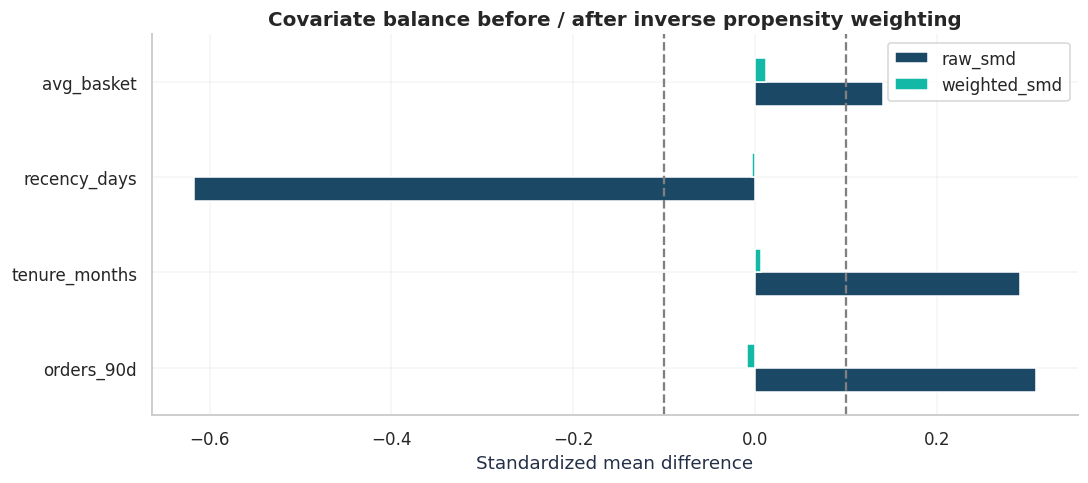

In [5]:
def smd(a,b):
    return (np.mean(a)-np.mean(b))/np.sqrt((np.var(a)+np.var(b))/2)
raw=[smd(X.loc[T==1,f],X.loc[T==0,f]) for f in features]
# Weighted group means and variances for standardized mean difference.
def wsmd(v):
    a=v[T==1];b=v[T==0]
    w1=1/ehat[T==1];w0=1/(1-ehat[T==0])
    m1=np.average(a,weights=w1);m0=np.average(b,weights=w0)
    var1=np.average((a-m1)**2,weights=w1);var0=np.average((b-m0)**2,weights=w0)
    return (m1-m0)/np.sqrt((var1+var0)/2)
weighted=[wsmd(X[f].to_numpy()) for f in features]
balance=pd.DataFrame({'feature':features,'raw_smd':raw,'weighted_smd':weighted})
display(balance.round(3))
ax=balance.set_index('feature')[['raw_smd','weighted_smd']].plot.barh(color=COLORS[:2]);ax.axvline(.1,ls='--',color='gray');ax.axvline(-.1,ls='--',color='gray')
ax.set(title='Covariate balance before / after inverse propensity weighting',xlabel='Standardized mean difference',ylabel='');plt.tight_layout();plt.show()

## 5. Segment effects (observational estimates)

,mean,se,count
recency_group,,,
0–45d,11.14%,1.49%,3763
46–90d,13.31%,1.30%,3954
91–150d,10.12%,1.22%,5283


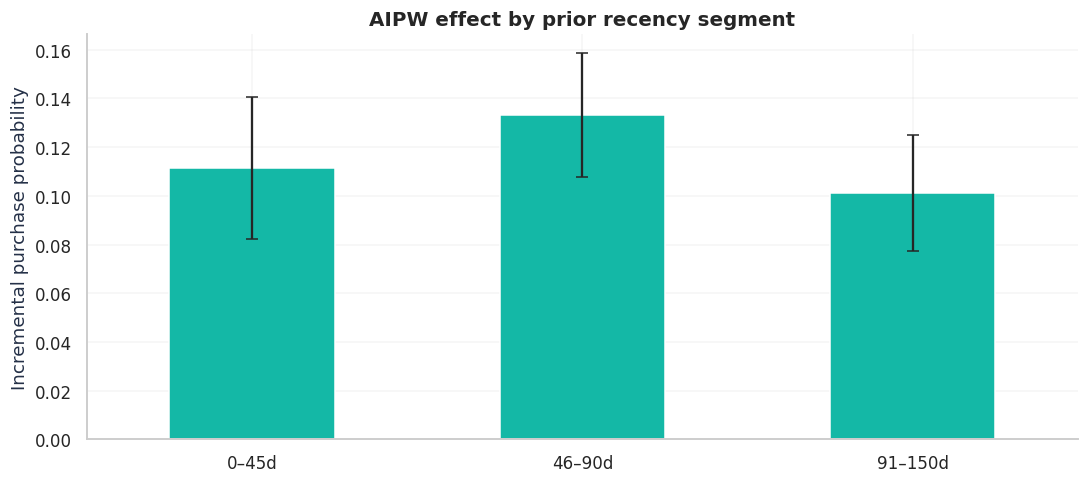

In [6]:
df['aipw_score']=pseudo
df['recency_group']=pd.cut(df.recency_days,bins=[0,45,90,151],labels=['0–45d','46–90d','91–150d'],right=False)
seg=df.groupby('recency_group',observed=True).aipw_score.agg(['mean','std','count'])
seg['se']=seg['std']/np.sqrt(seg['count'])
display(seg[['mean','se','count']].style.format({'mean':'{:.2%}','se':'{:.2%}'}))
ax=seg['mean'].plot.bar(yerr=1.96*seg['se'],rot=0,capsize=4,color=COLORS[1]);ax.set(title='AIPW effect by prior recency segment',ylabel='Incremental purchase probability',xlabel='');plt.tight_layout();plt.show()

## 6. Causal validity checklist

1. **Confounding:** include all drivers of both CRM selection and buying; synthetic data satisfies the stated conditioning assumption by construction.
2. **Positivity:** inspect propensity overlap, effective weights, and the trimmed population; do not extrapolate outside support.
3. **No leakage:** every nuisance prediction is out of fold, and only pre-treatment variables are used.
4. **Sensitivity:** test robustness to alternative covariate sets, trimming, and placebo outcomes; DoWhy can provide formal refuters in an optional extension.
5. **Business action:** prioritize high-ATE segments for **prospective randomized validation**, not instant deployment.